<a href="https://colab.research.google.com/github/hanna04107-wq/CPI-PREDICTION-USING-MACROECONOMIC-INDICATORS-AND-MACHINE-LEARNING-MODEL/blob/main/FYP_CPI_CODING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FYP: Peramalan CPI Malaysia Menggunakan Penunjuk Makroekonomi
**Struktur notebook** (ikut Bab 4):
1. Persediaan & data
2. EDA & ujian statistik
3. Pembahagian data & fungsi bantu
4. Model garis dasar (Naif, OLS, ARIMAX)
5. Model pembelajaran mesin (Lasso, Random Forest, XGBoost)
6. Perbandingan model
7. Ujian kepekaan (X berlengah 1 bulan)
8. Kebolehtafsiran (Kepentingan ciri & SHAP)

Setiap model mempunyai graf **berasingan** (sel sendiri): (a) CPI sebenar vs ramalan dengan kotak prestasi,
(b) data latihan + ujian + ramalan.

## 1. Persediaan & Data

In [ ]:
# Import & tetapan
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import shap
from scipy.stats import pearsonr, spearmanr
from statsmodels.tsa.stattools import kpss, adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import acorr_breusch_godfrey
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFECV
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
logging.getLogger("shap").setLevel(logging.ERROR)
plt.rcParams['figure.dpi'] = 100

RS = 42
FAIL = "/content/Final_Macroeconomic_Dataset_2013_2026_Jan.csv"

In [ ]:
# Muat data
df_data = pd.read_csv(FAIL)
df_data['Date'] = pd.to_datetime(df_data['Date'])
df_data = df_data.set_index('Date').sort_index()
df_data = df_data.drop(columns=['Year', 'Month'], errors='ignore')

print(df_data.info())
print("\nNilai hilang:\n", df_data.isna().sum())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 157 entries, 2013-01-01 to 2026-01-01
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CPI_Index          157 non-null    float64
 1   USD_Avg            157 non-null    float64
 2   M3_Total           157 non-null    float64
 3   OPR_Rate           157 non-null    float64
 4   PPI_Index          157 non-null    float64
 5   Unemployment_Rate  157 non-null    float64
dtypes: float64(6)
memory usage: 8.6 KB
None

Nilai hilang:
 CPI_Index            0
USD_Avg              0
M3_Total             0
OPR_Rate             0
PPI_Index            0
Unemployment_Rate    0
dtype: int64


## 2. Analisis Penerokaan Data (EDA) & Ujian Statistik
### 2.1 Analisis deskriptif

*Nota: ujian kepegunan, korelasi dan VIF menggunakan keseluruhan sampel untuk tujuan penerokaan sahaja; pemilihan model dan penalaan hiperparameter hanya menggunakan data latihan.*

       CPI_Index  USD_Avg     M3_Total  OPR_Rate  PPI_Index  Unemployment_Rate
count    157.000  157.000      157.000   157.000    157.000            157.000
mean     121.283    4.086  1939962.927     2.817    110.155              3.476
std        8.287    0.439   355827.364     0.498      6.765              0.549
min      105.900    3.017  1375858.000     1.750     99.000              2.600
25%      114.800    4.027  1611143.400     2.750    105.000              3.200
50%      120.900    4.178  1913308.500     3.000    108.300              3.300
75%      128.600    4.348  2257146.300     3.250    116.300              3.500
max      135.700    4.772  2591321.800     3.250    124.100              5.300


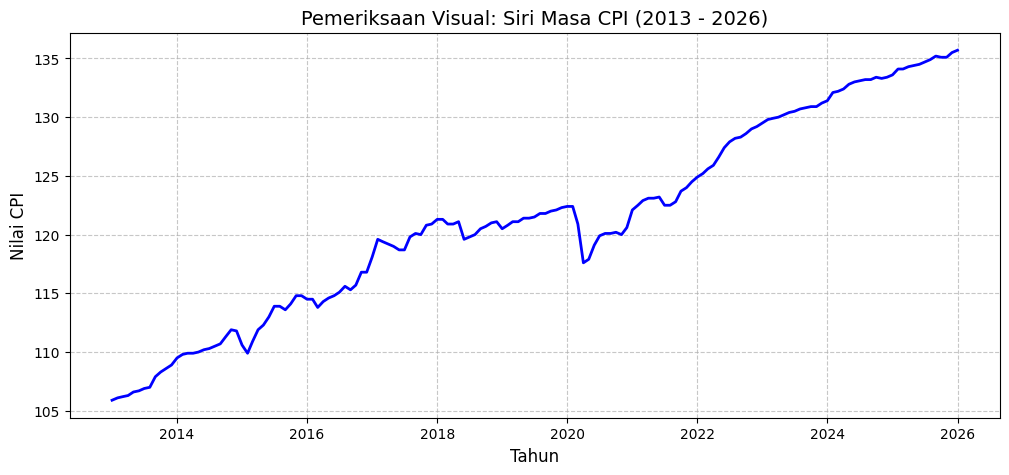

In [ ]:
# 4.2.1 Analisis deskriptif
print(df_data.describe().round(3))

plt.figure(figsize=(12, 5))
plt.plot(df_data.index, df_data['CPI_Index'], color='blue', linewidth=2)
plt.title('Pemeriksaan Visual: Siri Masa CPI (2013 - 2026)', fontsize=14)
plt.xlabel('Tahun', fontsize=12)
plt.ylabel('Nilai CPI', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 2.2 Ujian kepegunan (KPSS & ADF)
Pegun hanya jika **ADF p < 0.05** dan **KPSS p ≥ 0.05**.

In [ ]:
# 4.2.2 Ujian kepegunan
def ujian_kepegunan(siri, nama):
    s = siri.dropna()
    adf_stat, adf_p = adfuller(s, autolag='AIC')[:2]
    kpss_stat, kpss_p = kpss(s, regression='c', nlags='auto')[:2]
    return {'Pembolehubah': nama,
            'ADF stat': round(adf_stat, 4), 'ADF p': round(adf_p, 4),
            'KPSS stat': round(kpss_stat, 4), 'KPSS p*': round(kpss_p, 4),
            'Pegun': (adf_p < 0.05) and (kpss_p >= 0.05)}

semua_var = ['CPI_Index', 'OPR_Rate', 'PPI_Index', 'Unemployment_Rate', 'M3_Total', 'USD_Avg']

jadual_asal = pd.DataFrame([ujian_kepegunan(df_data[c], c) for c in semua_var])
print("=== Aras asal ===")
print(jadual_asal.to_string(index=False))
print("* statsmodels menghadkan nilai-p KPSS pada julat 0.01 - 0.10")

perlu_diff = jadual_asal.loc[~jadual_asal['Pegun'], 'Pembolehubah'].tolist()
print("\nPerlu pembezaan:", perlu_diff)

# Buang lajur *_diff sedia ada supaya sel ini selamat dijalankan berulang kali
df_data = df_data.drop(columns=[c for c in df_data.columns if c.endswith('_diff')])
for c in perlu_diff:
    df_data[c + '_diff'] = df_data[c].diff()

jadual_diff = pd.DataFrame([ujian_kepegunan(df_data[c + '_diff'], c + '_diff') for c in perlu_diff])
print("\n=== Selepas pembezaan pertama ===")
print(jadual_diff.to_string(index=False))
assert 'CPI_Index' in perlu_diff, "CPI sepatutnya tidak pegun pada aras asal"
if not jadual_diff['Pegun'].all():
    print("AMARAN: ada siri yang masih tidak pegun selepas d=1 - semak semula.")

df_data = df_data.rename(columns={'CPI_Index_diff': 'CPI_diff'})   # nama sasaran konsisten
assert 'CPI_diff' in df_data.columns

=== Aras asal ===
     Pembolehubah  ADF stat  ADF p  KPSS stat  KPSS p*  Pegun
        CPI_Index   -0.7176 0.8421     1.7615   0.0100  False
         OPR_Rate   -1.7387 0.4113     0.5014   0.0414  False
        PPI_Index   -1.4859 0.5405     1.0281   0.0100  False
Unemployment_Rate   -1.8898 0.3369     0.3922   0.0805  False
         M3_Total    1.0199 0.9945     1.8468   0.0100  False
          USD_Avg   -2.3845 0.1461     1.1980   0.0100  False
* statsmodels menghadkan nilai-p KPSS pada julat 0.01 - 0.10

Perlu pembezaan: ['CPI_Index', 'OPR_Rate', 'PPI_Index', 'Unemployment_Rate', 'M3_Total', 'USD_Avg']

=== Selepas pembezaan pertama ===
          Pembolehubah  ADF stat  ADF p  KPSS stat  KPSS p*  Pegun
        CPI_Index_diff   -9.2793  0.000     0.0649      0.1   True
         OPR_Rate_diff   -5.2158  0.000     0.1093      0.1   True
        PPI_Index_diff   -8.0772  0.000     0.0925      0.1   True
Unemployment_Rate_diff   -8.2912  0.000     0.1193      0.1   True
         M3_Tota

In [ ]:
# Senarai pembolehubah model
x_asal = [c for c in semua_var if c != 'CPI_Index']
senarai_x = [c + '_diff' if c in perlu_diff else c for c in x_asal]
print("Pembolehubah X untuk model:", senarai_x)

df_bersih = df_data.dropna().copy()
print("Bilangan pemerhatian selepas buang NaN:", len(df_bersih))

Pembolehubah X untuk model: ['OPR_Rate_diff', 'PPI_Index_diff', 'Unemployment_Rate_diff', 'M3_Total_diff', 'USD_Avg_diff']
Bilangan pemerhatian selepas buang NaN: 156


### 2.3 Korelasi Pearson

          Pembolehubah       r  nilai-p
Unemployment_Rate_diff -0.5397   0.0000
        PPI_Index_diff  0.3191   0.0000
         M3_Total_diff -0.0811   0.3143
          USD_Avg_diff -0.0793   0.3250
         OPR_Rate_diff  0.0683   0.3966


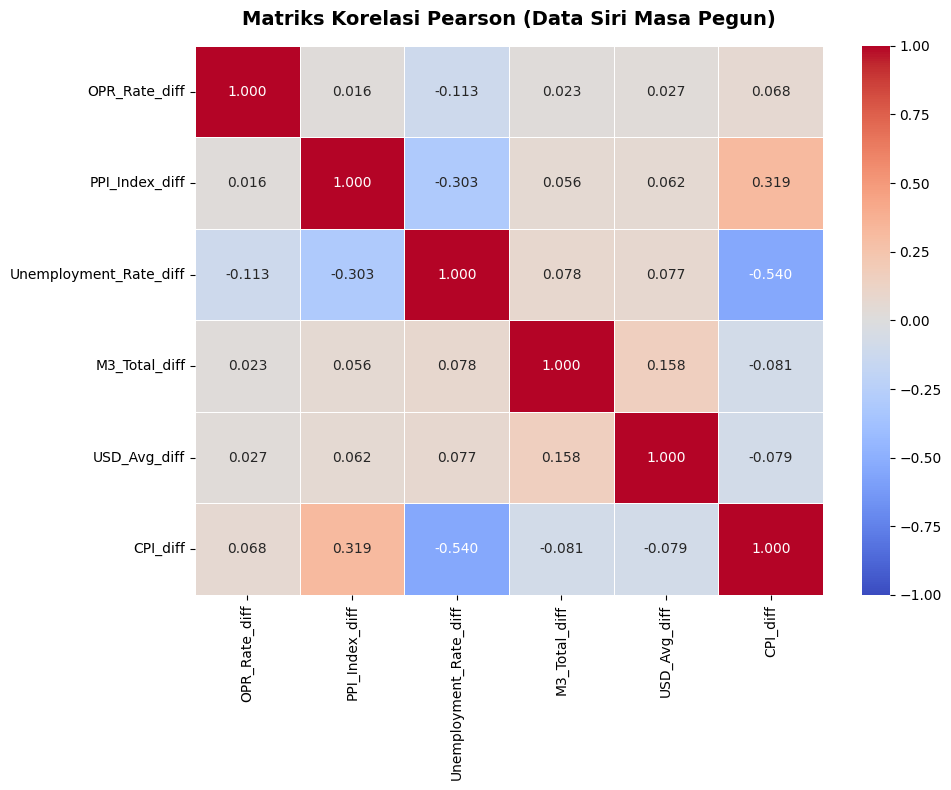

In [ ]:
# 4.2.3 Korelasi Pearson (dengan nilai-p)
matriks_korelasi = df_bersih[senarai_x + ['CPI_diff']].corr()

korelasi_cpi = pd.DataFrame(
    [{'Pembolehubah': c, 'r': pearsonr(df_bersih[c], df_bersih['CPI_diff'])[0],
      'nilai-p': pearsonr(df_bersih[c], df_bersih['CPI_diff'])[1]} for c in senarai_x]
).sort_values('r', key=np.abs, ascending=False).reset_index(drop=True)
print(korelasi_cpi.round(4).to_string(index=False))

plt.figure(figsize=(10, 8))
sns.heatmap(matriks_korelasi, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Matriks Korelasi Pearson (Data Siri Masa Pegun)", fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 2.4 Multikolineariti (VIF)

In [ ]:
# 4.2.4 VIF
X_vif = sm.add_constant(df_bersih[senarai_x])
data_vif = pd.DataFrame({'Pembolehubah X': X_vif.columns,
                         'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]})
data_vif = data_vif[data_vif['Pembolehubah X'] != 'const'].sort_values('VIF', ascending=False).reset_index(drop=True)
print(data_vif.round(4).to_string(index=False))

        Pembolehubah X    VIF
Unemployment_Rate_diff 1.1372
        PPI_Index_diff 1.1167
          USD_Avg_diff 1.0375
         M3_Total_diff 1.0365
         OPR_Rate_diff 1.0158


## 3. Pembahagian Data & Fungsi Bantu

In [ ]:
# Pembahagian data latihan / ujian (kronologi 80/20)
saiz_latihan = int(len(df_bersih) * 0.8)
X_latih = df_bersih[senarai_x].iloc[:saiz_latihan]
X_uji   = df_bersih[senarai_x].iloc[saiz_latihan:]
y_latih_diff = df_bersih['CPI_diff'].iloc[:saiz_latihan]
y_uji_diff   = df_bersih['CPI_diff'].iloc[saiz_latihan:]
y_latih_asal = df_bersih['CPI_Index'].iloc[:saiz_latihan]
y_uji_asal   = df_bersih['CPI_Index'].iloc[saiz_latihan:]
cpi_terakhir = y_latih_asal.iloc[-1]        # titik permulaan transformasi songsang (cumsum)
n_uji = len(X_uji)
tscv = TimeSeriesSplit(n_splits=5)

print(f"Jumlah        : {len(df_bersih)} bulan")
print(f"Latihan (80%) : {len(X_latih)} bulan ({X_latih.index[0].date()} - {X_latih.index[-1].date()})")
print(f"Ujian   (20%) : {len(X_uji)} bulan ({X_uji.index[0].date()} - {X_uji.index[-1].date()})")

Jumlah        : 156 bulan
Latihan (80%) : 124 bulan (2013-02-01 - 2023-05-01)
Ujian   (20%) : 32 bulan (2023-06-01 - 2026-01-01)


In [ ]:
# Fungsi penilaian & graf (digunakan oleh semua model)
hasil, metrik, ramalan_index = [], {}, {}

def nilai(nama, pred_diff=None, pred_index=None):
    """Nilai ramalan pada aras indeks CPI DAN perubahan bulanan (CPI_diff)."""
    if pred_index is None:
        pred_index = cpi_terakhir + np.cumsum(np.asarray(pred_diff, dtype=float))
    pred_index = np.asarray(pred_index, dtype=float)
    pred_diff = np.diff(np.r_[cpi_terakhir, pred_index])
    ramalan_index[nama] = pred_index
    rekod = {'Model': nama,
             'R2 (indeks)':   r2_score(y_uji_asal, pred_index),
             'MAE (indeks)':  mean_absolute_error(y_uji_asal, pred_index),
             'RMSE (indeks)': float(np.sqrt(mean_squared_error(y_uji_asal, pred_index))),
             'R2 (diff)':     r2_score(y_uji_diff, pred_diff),
             'MAE (diff)':    mean_absolute_error(y_uji_diff, pred_diff),
             'RMSE (diff)':   float(np.sqrt(mean_squared_error(y_uji_diff, pred_diff)))}
    hasil.append(rekod)
    metrik[nama] = rekod
    print(f"{nama:34s} indeks: R2={rekod['R2 (indeks)']:.4f} MAE={rekod['MAE (indeks)']:.4f} RMSE={rekod['RMSE (indeks)']:.4f}"
          f"  |  diff: R2={rekod['R2 (diff)']:.4f} RMSE={rekod['RMSE (diff)']:.4f}")

def graf_ramalan(nama, warna, penanda='o', tajuk_pendek=None):
    """Graf (a): CPI sebenar vs ramalan pada data ujian, dengan kotak prestasi."""
    m = metrik[nama]
    label = tajuk_pendek or nama
    plt.figure(figsize=(12, 6))
    plt.plot(y_uji_asal.index, y_uji_asal.values, label='CPI Sebenar (Ujian)',
             color='blue', linewidth=2, marker='o', markersize=4)
    plt.plot(y_uji_asal.index, ramalan_index[nama], label=f'Ramalan CPI ({label})',
             color=warna, linestyle='--', linewidth=2, marker=penanda, markersize=4)
    plt.title(f'Perbandingan CPI Sebenar vs Ramalan {label} Pada Data Ujian', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Bulan / Tahun', fontsize=12)
    plt.ylabel('Indeks Harga Pengguna (CPI)', fontsize=12)
    plt.legend(loc='upper left', fontsize=11)
    plt.grid(True, linestyle=':', alpha=0.7)
    kotak = (f"Prestasi {label}:\nR² = {m['R2 (indeks)']:.4f}\nMAE = {m['MAE (indeks)']:.4f}\n"
             f"RMSE = {m['RMSE (indeks)']:.4f}\nRMSE (Δ bulanan) = {m['RMSE (diff)']:.4f}")
    plt.text(0.70, 0.05, kotak, transform=plt.gca().transAxes, fontsize=10,
             bbox=dict(facecolor='white', alpha=0.9, edgecolor='gray', boxstyle='round,pad=0.5'))
    plt.tight_layout()
    plt.show()

def graf_latih_uji(nama, warna, tajuk_pendek=None):
    """Graf (b): data latihan + data ujian sebenar + ramalan."""
    label = tajuk_pendek or nama
    plt.figure(figsize=(11, 6))
    plt.plot(y_latih_asal, label='Data Latihan (80%)', color='blue', alpha=0.7)
    plt.plot(y_uji_asal, label='Data Ujian Sebenar (20%)', color='orange', linewidth=2)
    plt.plot(y_uji_asal.index, ramalan_index[nama], label=f'Ramalan {label}',
             color=warna, linestyle='--', linewidth=2)
    plt.title(f'Prestasi {label}: Nilai Sebenar vs Ramalan Indeks Harga Pengguna (CPI)', fontsize=14, fontweight='bold')
    plt.xlabel('Tahun', fontsize=12)
    plt.ylabel('Nilai Indeks CPI', fontsize=12)
    plt.legend(loc='upper left')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

## 4. Model Garis Dasar
### 4.1 Penanda aras naif (Random Walk & Drift)
Model sebenar mesti mengatasi penanda aras ini untuk dianggap menambah nilai.

In [ ]:
# Penanda aras naif
nilai('Naif: Random Walk', pred_diff=np.zeros(n_uji))
nilai('Naif: Drift', pred_diff=np.full(n_uji, y_latih_diff.mean()))

Naif: Random Walk                  indeks: R2=-3.3474 MAE=2.9281 RMSE=3.3370  |  diff: R2=-1.1191 RMSE=0.2365
Naif: Drift                        indeks: R2=0.9235 MAE=0.3643 RMSE=0.4425  |  diff: R2=-0.0220 RMSE=0.1642


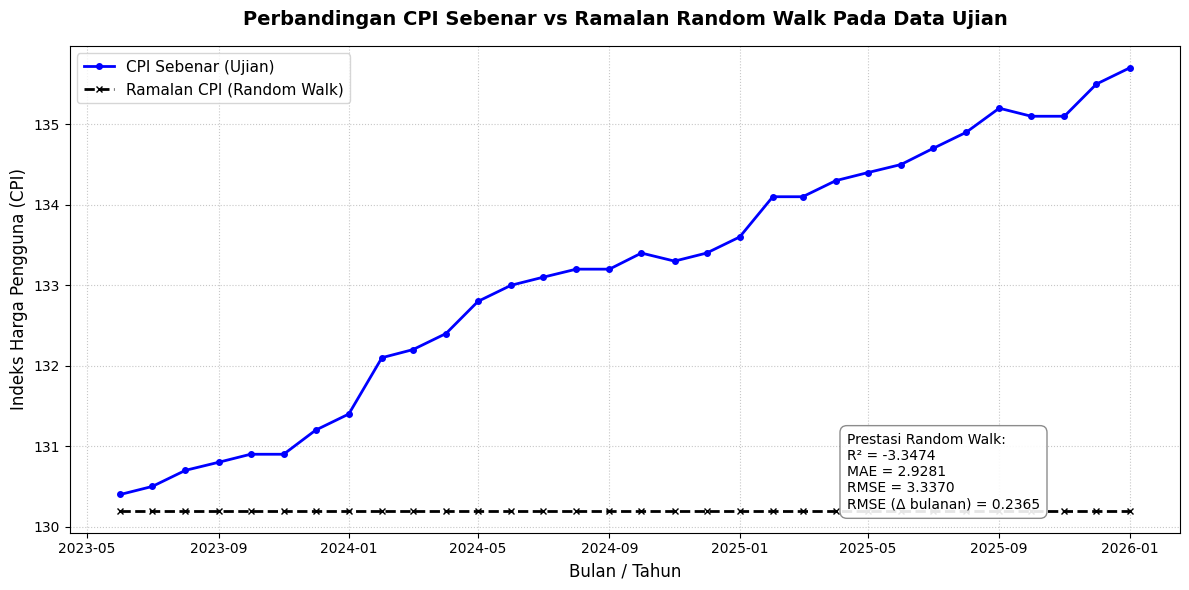

In [ ]:
# Graf: Naif Random Walk
graf_ramalan('Naif: Random Walk', 'black', 'x', tajuk_pendek='Random Walk')

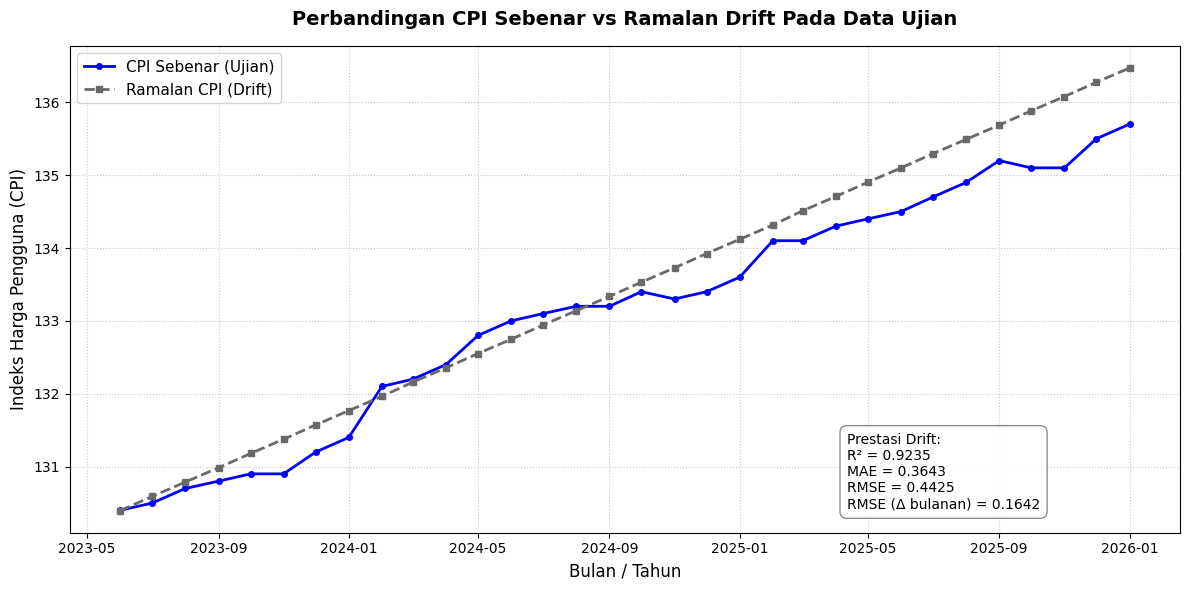

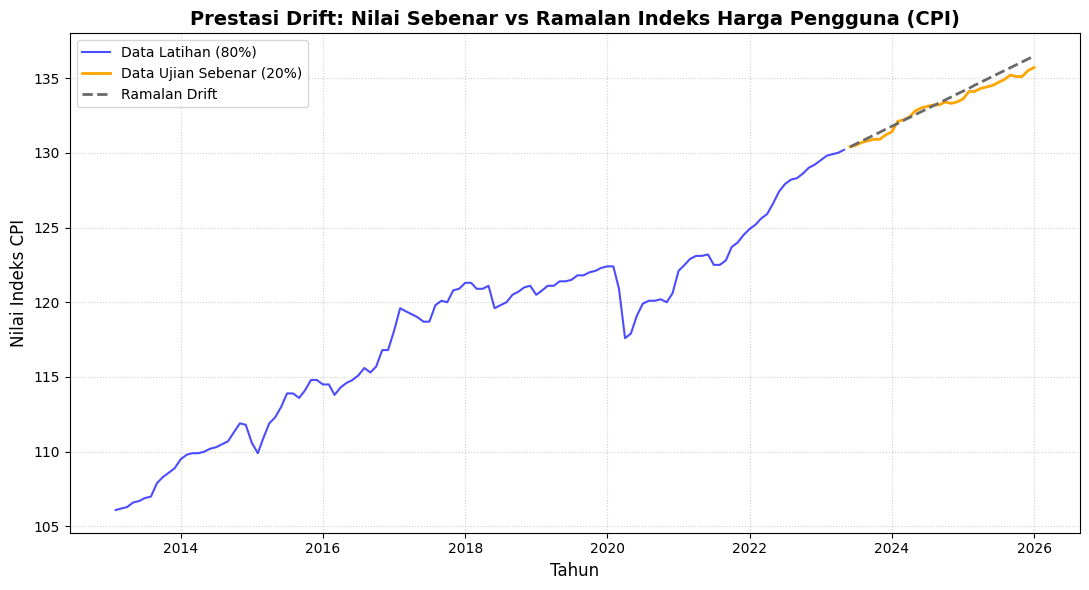

In [ ]:
# Graf: Naif Drift
graf_ramalan('Naif: Drift', 'dimgray', 's', tajuk_pendek='Drift')
graf_latih_uji('Naif: Drift', 'dimgray', tajuk_pendek='Drift')

### 4.2 OLS

In [ ]:
# 4.3.1 OLS
X_latih_ols = sm.add_constant(X_latih)
X_uji_ols = sm.add_constant(X_uji, has_constant='add')

keputusan_ols = sm.OLS(y_latih_diff, X_latih_ols).fit()
print(keputusan_ols.summary())

bg = acorr_breusch_godfrey(keputusan_ols, nlags=6)
print("\nDurbin-Watson :", round(durbin_watson(keputusan_ols.resid), 4))
print(f"Breusch-Godfrey (6 lag): LM={bg[0]:.4f}, p={bg[1]:.4f}  (p<0.05 => ada autokorelasi)")

ols_hac = sm.OLS(y_latih_diff, X_latih_ols).fit(cov_type='HAC', cov_kwds={'maxlags': 3})
print("\n=== Pekali dengan ralat piawai teguh (HAC) ===")
print(ols_hac.summary().tables[1])

nilai('OLS', pred_diff=keputusan_ols.predict(X_uji_ols))

                            OLS Regression Results                            
Dep. Variable:               CPI_diff   R-squared:                       0.339
Model:                            OLS   Adj. R-squared:                  0.311
Method:                 Least Squares   F-statistic:                     12.10
Date:                Thu, 08 Oct 2026   Prob (F-statistic):           1.80e-09
Time:                        10:21:57   Log-Likelihood:                -79.432
No. Observations:                 124   AIC:                             170.9
Df Residuals:                     118   BIC:                             187.8
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      0

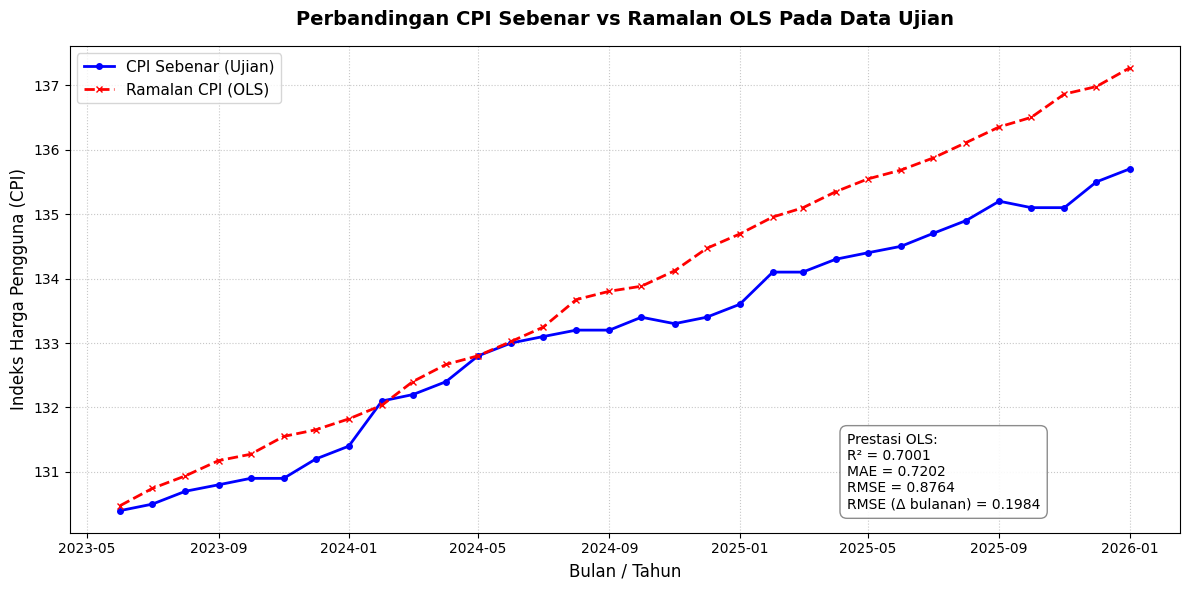

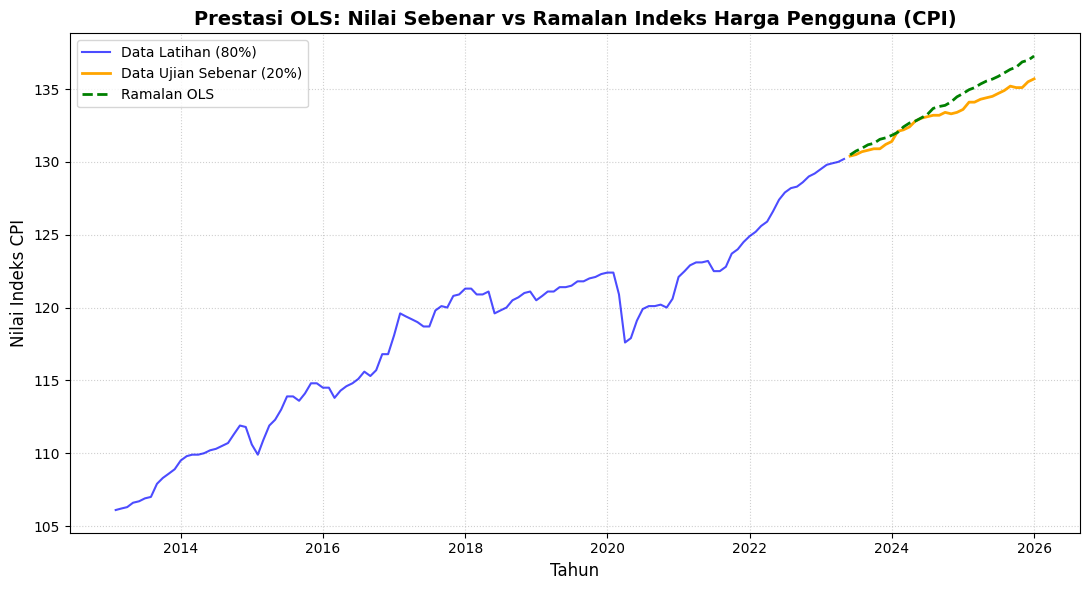

In [ ]:
# Graf: OLS
graf_ramalan('OLS', 'red', 'x')
graf_latih_uji('OLS', 'green')

### 4.3 ARIMAX (siri dibezakan, d=0)

In [ ]:
# 4.3.2 ARIMAX pada CPI_diff
best_aic, best_order, best_arimax = np.inf, None, None
for p in range(4):
    for q in range(4):
        try:
            m = SARIMAX(y_latih_diff, exog=X_latih, order=(p, 0, q), trend='c').fit(disp=False)
            if m.aic < best_aic:
                best_aic, best_order, best_arimax = m.aic, (p, 0, q), m
        except Exception:
            continue
print(f">> ARIMAX terbaik: {best_order}  AIC={best_aic:.4f}")
print(best_arimax.summary())

pred = best_arimax.get_forecast(steps=n_uji, exog=X_uji).predicted_mean
nama_arimax = f'ARIMAX{best_order} (d=0)'
nilai(nama_arimax, pred_diff=pred)

>> ARIMAX terbaik: (0, 0, 0)  AIC=177.4475
                               SARIMAX Results                                
Dep. Variable:               CPI_diff   No. Observations:                  124
Model:                        SARIMAX   Log Likelihood                 -81.724
Date:                Thu, 08 Oct 2026   AIC                            177.447
Time:                        10:22:25   BIC                            197.189
Sample:                    02-01-2013   HQIC                           185.467
                         - 05-01-2023                                         
Covariance Type:                  opg                                         
                             coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------
intercept                  0.1359      0.056      2.448      0.014       0.027       0.245
OPR_Rate_diff              0.0233      0.496      0.

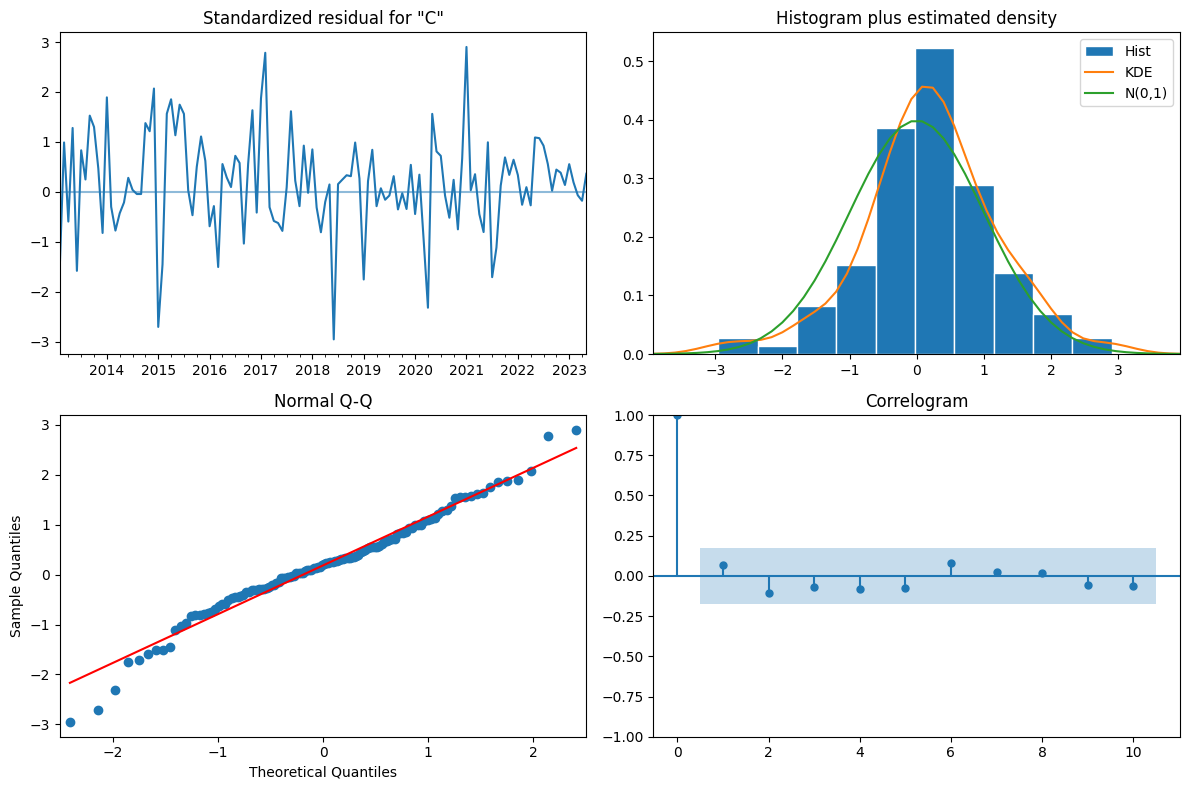

In [ ]:
# Graf: diagnostik ARIMAX
best_arimax.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()

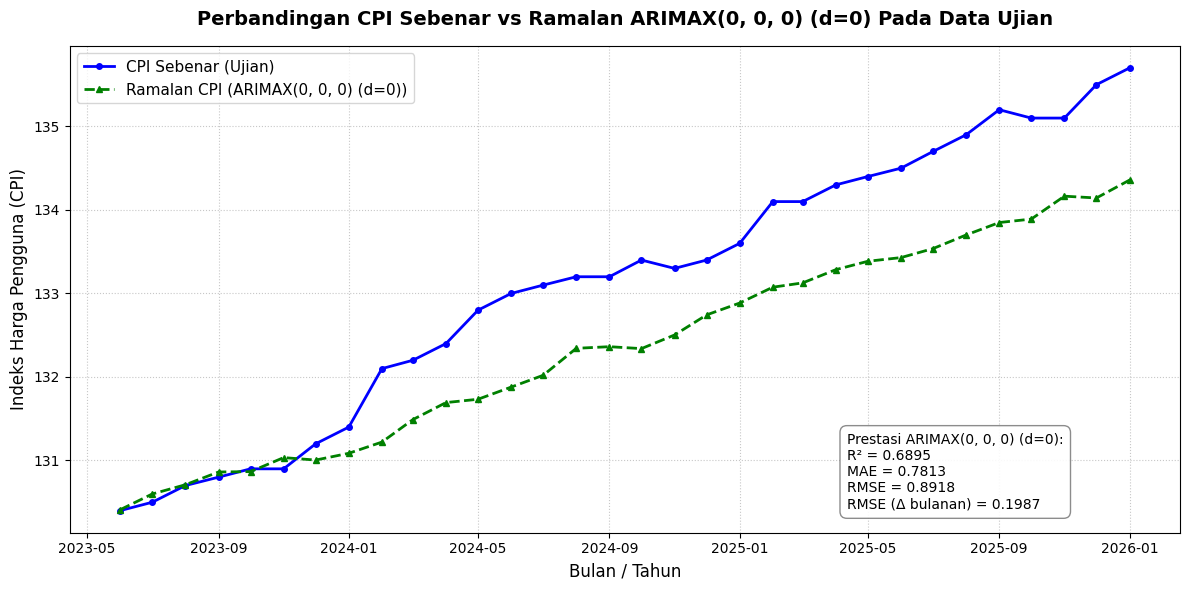

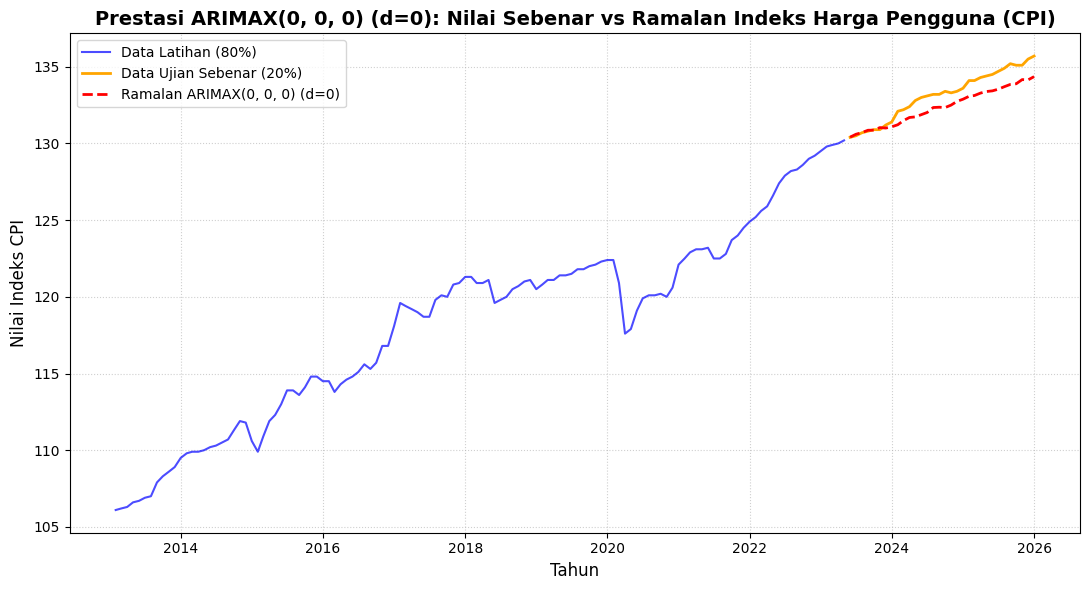

In [ ]:
# Graf: ARIMAX (d=0)
graf_ramalan(nama_arimax, 'green', '^')
graf_latih_uji(nama_arimax, 'red')

### 4.4 ARIMAX pada aras asal (d=1 ditetapkan)
AIC antara nilai d yang berbeza tidak boleh dibandingkan, maka d ditetapkan =1 dan hanya (p, q) dicari.

In [ ]:
# ARIMAX aras asal
X_latih_raw = df_bersih[x_asal].iloc[:saiz_latihan]
X_uji_raw = df_bersih[x_asal].iloc[saiz_latihan:]

best_aic_r, best_order_r, best_arimax_r = np.inf, None, None
for p in range(4):
    for q in range(4):
        try:
            m = SARIMAX(y_latih_asal, exog=X_latih_raw, order=(p, 1, q), trend='c').fit(disp=False)
            if m.aic < best_aic_r:
                best_aic_r, best_order_r, best_arimax_r = m.aic, (p, 1, q), m
        except Exception:
            continue
print(f">> ARIMAX (aras asal, d=1) terbaik: {best_order_r}  AIC={best_aic_r:.4f}")
print(best_arimax_r.summary())

pred_r = best_arimax_r.get_forecast(steps=n_uji, exog=X_uji_raw).predicted_mean
nama_arimax_raw = f'ARIMAX{best_order_r} (aras asal)'
nilai(nama_arimax_raw, pred_index=pred_r)

>> ARIMAX (aras asal, d=1) terbaik: (0, 1, 0)  AIC=174.4232
                               SARIMAX Results                                
Dep. Variable:              CPI_Index   No. Observations:                  124
Model:               SARIMAX(0, 1, 0)   Log Likelihood                 -80.212
Date:                Thu, 08 Oct 2026   AIC                            174.423
Time:                        10:22:54   BIC                            194.108
Sample:                    02-01-2013   HQIC                           182.419
                         - 05-01-2023                                         
Covariance Type:                  opg                                         
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
intercept             0.1405      0.055      2.553      0.011       0.033       0.248
OPR_Rate              0.0051      0.489      0.010

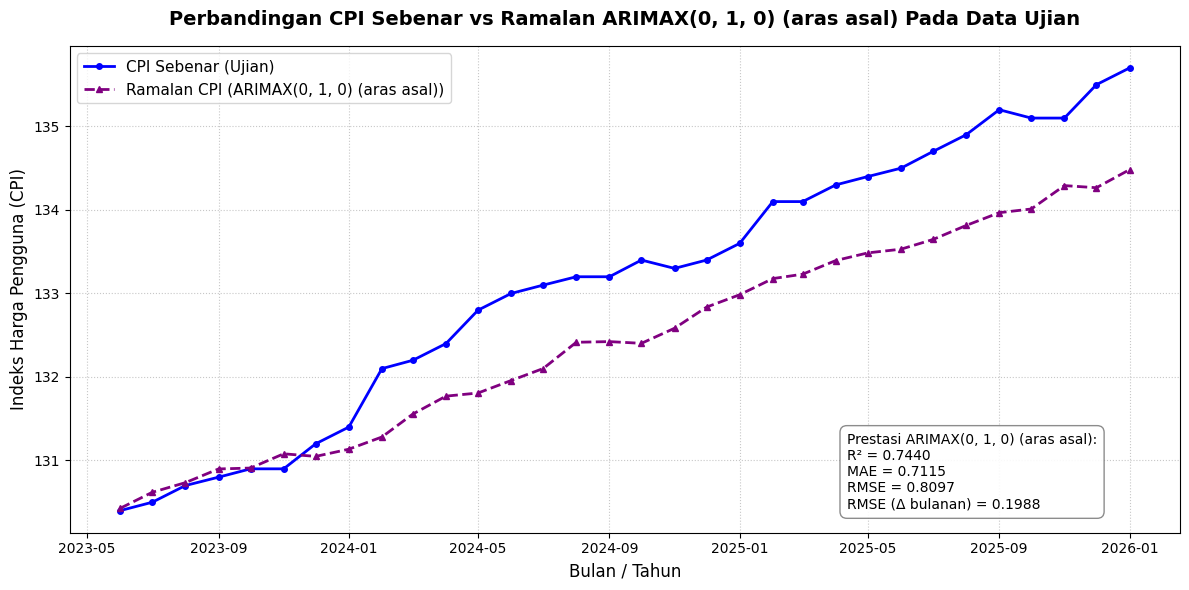

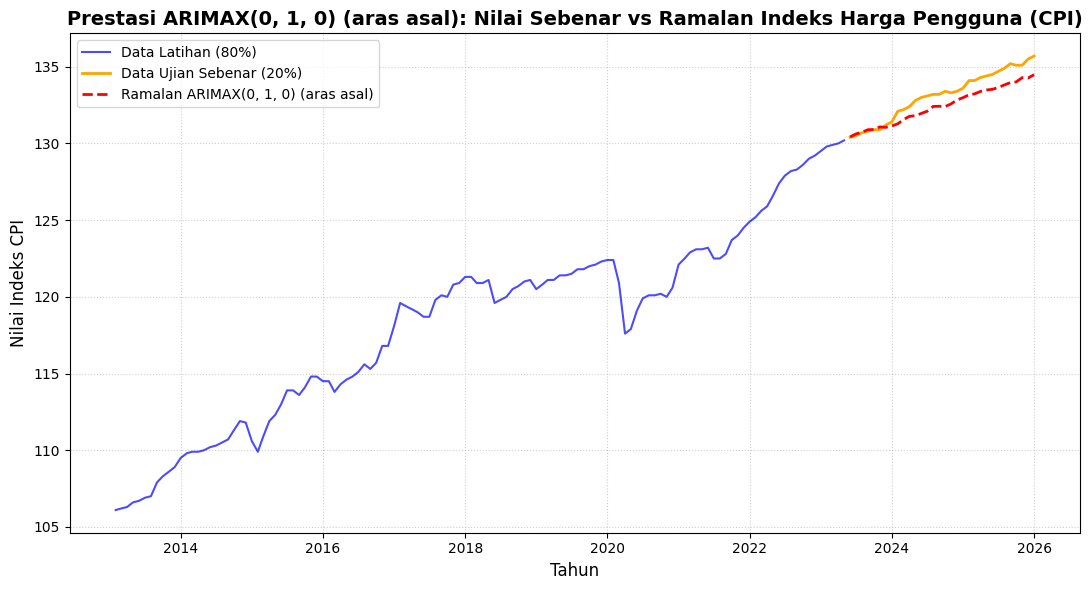

In [ ]:
# Graf: ARIMAX aras asal
graf_ramalan(nama_arimax_raw, 'purple', '^')
graf_latih_uji(nama_arimax_raw, 'red')

## 5. Model Pembelajaran Mesin
### 5.1 Regresi Lasso

In [ ]:
# 4.4.1 Lasso
pipe_lasso = Pipeline([('scaler', StandardScaler()), ('lasso', Lasso(max_iter=20000, random_state=RS))])
gs_lasso = GridSearchCV(pipe_lasso, {'lasso__alpha': np.logspace(-4, 1, 30)},
                        cv=tscv, scoring='neg_mean_absolute_error', n_jobs=-1)
gs_lasso.fit(X_latih, y_latih_diff)
model_lasso = gs_lasso.best_estimator_
print("Alpha terbaik:", gs_lasso.best_params_['lasso__alpha'])

pekali = pd.DataFrame({'Pembolehubah': senarai_x, 'Pekali': model_lasso.named_steps['lasso'].coef_})
pekali['|Pekali|'] = pekali['Pekali'].abs()
print(pekali.sort_values('|Pekali|', ascending=False).to_string(index=False))
print("Digugurkan (pekali=0):", pekali.loc[pekali['Pekali'] == 0, 'Pembolehubah'].tolist())

nilai('Lasso', pred_diff=model_lasso.predict(X_uji))

Alpha terbaik: 0.03856620421163472
          Pembolehubah    Pekali  |Pekali|
Unemployment_Rate_diff -0.252072  0.252072
        PPI_Index_diff  0.066588  0.066588
          USD_Avg_diff -0.000175  0.000175
         OPR_Rate_diff  0.000000  0.000000
         M3_Total_diff -0.000000  0.000000
Digugurkan (pekali=0): ['OPR_Rate_diff', 'M3_Total_diff']
Lasso                              indeks: R2=0.7437 MAE=0.6880 RMSE=0.8102  |  diff: R2=-0.3295 RMSE=0.1873


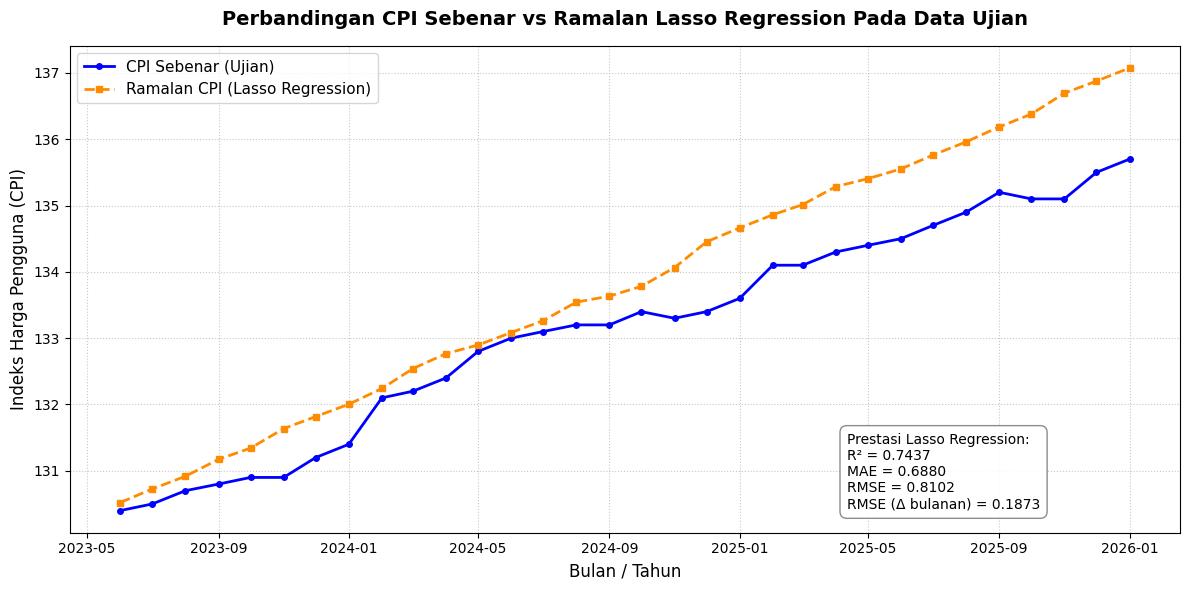

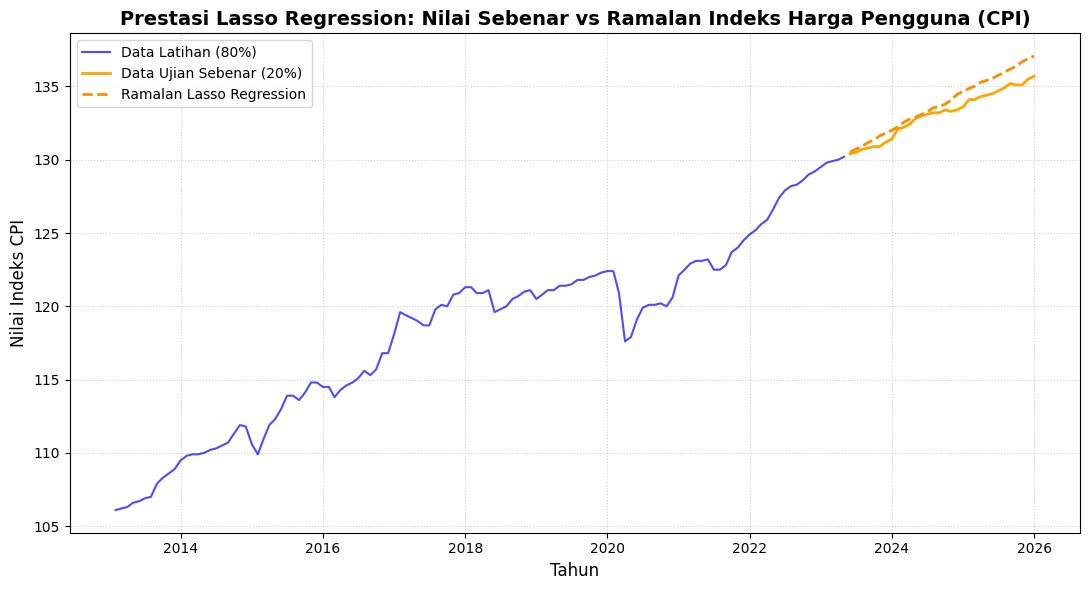

In [ ]:
# Graf: Lasso
graf_ramalan('Lasso', 'darkorange', 's', tajuk_pendek='Lasso Regression')
graf_latih_uji('Lasso', 'darkorange', tajuk_pendek='Lasso Regression')

### 5.2 Random Forest

In [ ]:
# 4.4.2 Random Forest (dengan RFE)
grid_rf = {'n_estimators': [50, 100, 200, 300], 'max_depth': [None, 3, 5, 10], 'min_samples_leaf': [1, 3, 5]}

rfecv_rf = RFECV(RandomForestRegressor(random_state=RS), step=1, cv=tscv,
                 scoring='neg_mean_absolute_error', n_jobs=-1)
rfecv_rf.fit(X_latih, y_latih_diff)
fitur_rf = [c for c, s in zip(senarai_x, rfecv_rf.support_) if s]
print("RFE-RF mengekalkan:", fitur_rf, "| digugurkan:", [c for c in senarai_x if c not in fitur_rf])

gs_rf_rfe = GridSearchCV(RandomForestRegressor(random_state=RS), grid_rf, cv=tscv,
                         scoring='neg_mean_absolute_error', n_jobs=-1)
gs_rf_rfe.fit(X_latih[fitur_rf], y_latih_diff)
print("RF + RFE parameter:", gs_rf_rfe.best_params_)
nilai('Random Forest + RFE', pred_diff=gs_rf_rfe.best_estimator_.predict(X_uji[fitur_rf]))

RFE-RF mengekalkan: ['PPI_Index_diff', 'Unemployment_Rate_diff', 'M3_Total_diff'] | digugurkan: ['OPR_Rate_diff', 'USD_Avg_diff']
RF + RFE parameter: {'max_depth': 3, 'min_samples_leaf': 5, 'n_estimators': 200}
Random Forest + RFE                indeks: R2=0.8785 MAE=0.5057 RMSE=0.5578  |  diff: R2=-0.3047 RMSE=0.1856


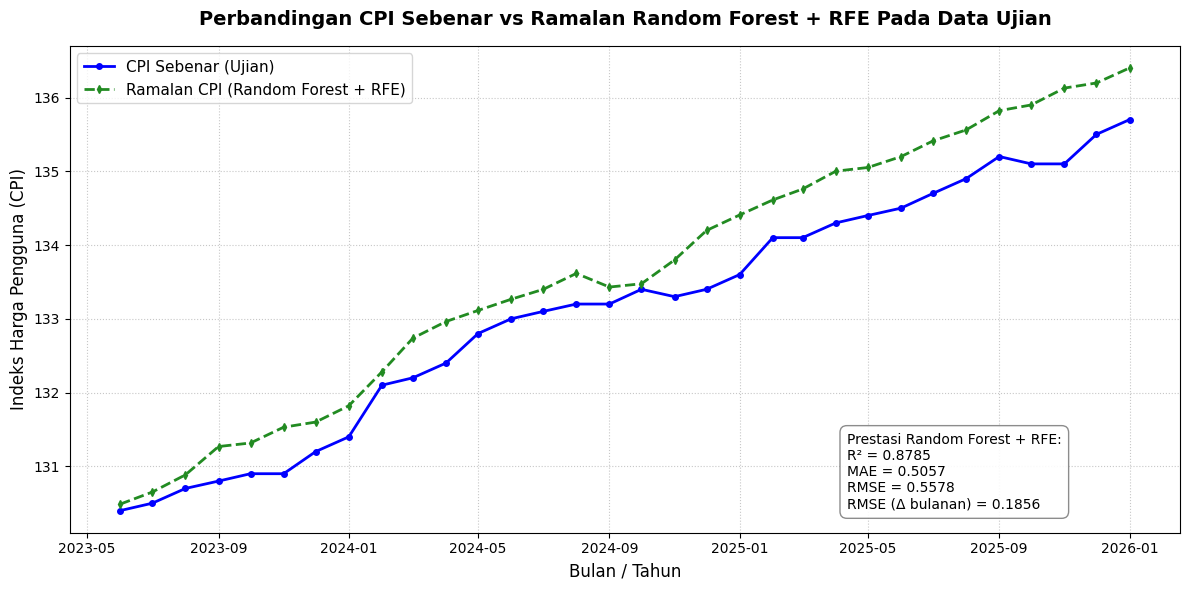

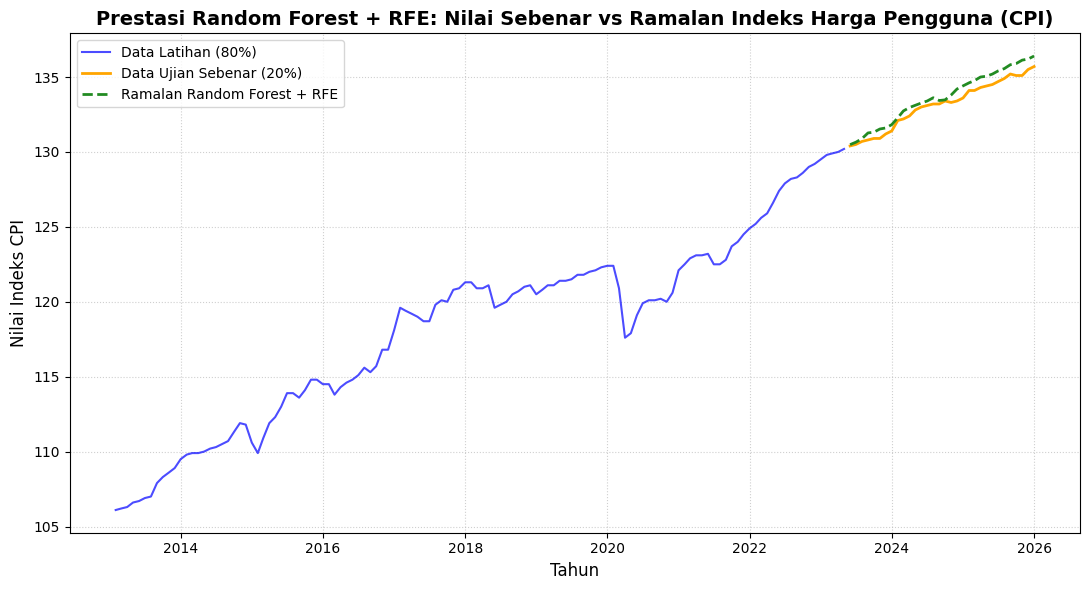

In [ ]:
# Graf: Random Forest + RFE
graf_ramalan('Random Forest + RFE', 'forestgreen', 'd')
graf_latih_uji('Random Forest + RFE', 'forestgreen')

In [ ]:
# 4.4.2 Random Forest (tanpa RFE)
gs_rf = GridSearchCV(RandomForestRegressor(random_state=RS), grid_rf, cv=tscv,
                     scoring='neg_mean_absolute_error', n_jobs=-1)
gs_rf.fit(X_latih, y_latih_diff)
model_rf = gs_rf.best_estimator_
print("RF tanpa RFE parameter:", gs_rf.best_params_)
nilai('Random Forest (Tanpa RFE)', pred_diff=model_rf.predict(X_uji))

RF tanpa RFE parameter: {'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 200}
Random Forest (Tanpa RFE)          indeks: R2=0.8299 MAE=0.5418 RMSE=0.6601  |  diff: R2=-0.0922 RMSE=0.1698


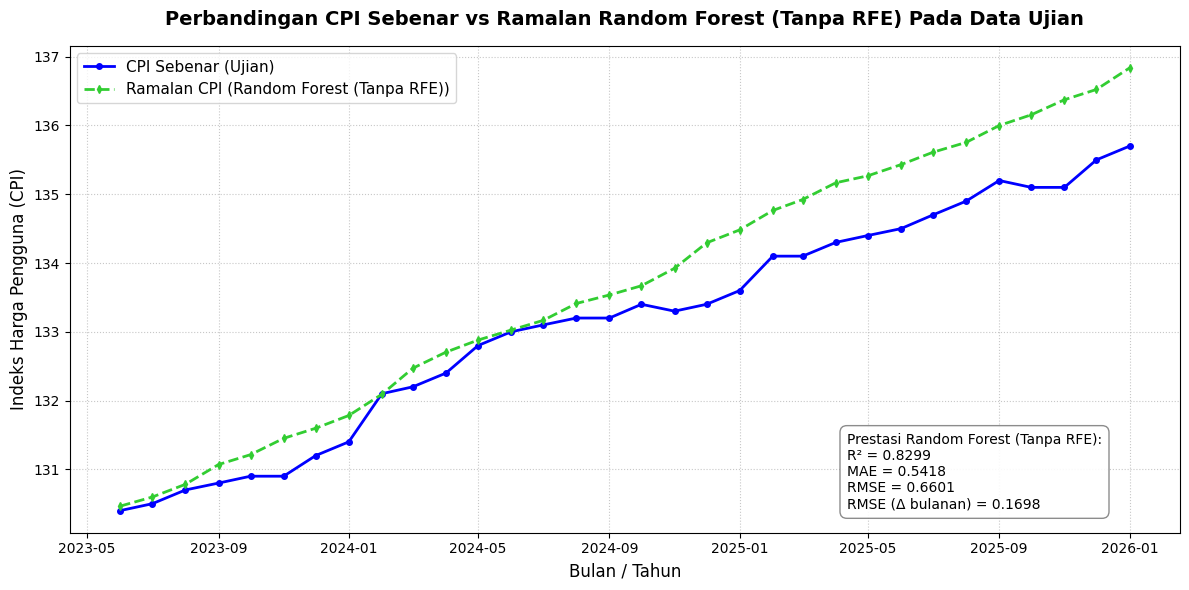

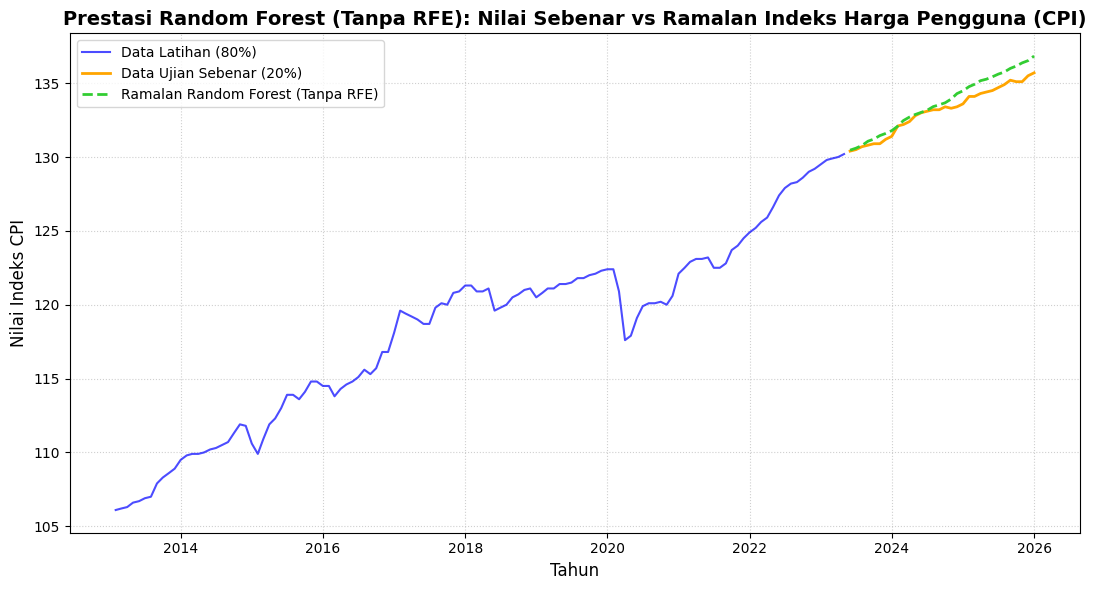

In [ ]:
# Graf: Random Forest tanpa RFE
graf_ramalan('Random Forest (Tanpa RFE)', 'limegreen', 'd')
graf_latih_uji('Random Forest (Tanpa RFE)', 'limegreen')

### 5.3 XGBoost

In [ ]:
# 4.4.3 XGBoost (dengan RFE)
grid_xgb = {'n_estimators': [50, 100, 200, 300], 'learning_rate': [0.01, 0.05, 0.1, 0.2], 'max_depth': [2, 3, 5]}

rfecv_xgb = RFECV(XGBRegressor(objective='reg:squarederror', random_state=RS), step=1, cv=tscv,
                  scoring='neg_mean_absolute_error', n_jobs=-1)
rfecv_xgb.fit(X_latih, y_latih_diff)
fitur_xgb = [c for c, s in zip(senarai_x, rfecv_xgb.support_) if s]
print("RFE-XGB mengekalkan:", fitur_xgb, "| digugurkan:", [c for c in senarai_x if c not in fitur_xgb])

gs_xgb_rfe = GridSearchCV(XGBRegressor(objective='reg:squarederror', random_state=RS), grid_xgb, cv=tscv,
                          scoring='neg_mean_absolute_error', n_jobs=-1)
gs_xgb_rfe.fit(X_latih[fitur_xgb], y_latih_diff)
print("XGB + RFE parameter:", gs_xgb_rfe.best_params_)
nilai('XGBoost + RFE', pred_diff=gs_xgb_rfe.best_estimator_.predict(X_uji[fitur_xgb]))

RFE-XGB mengekalkan: ['Unemployment_Rate_diff'] | digugurkan: ['OPR_Rate_diff', 'PPI_Index_diff', 'M3_Total_diff', 'USD_Avg_diff']
XGB + RFE parameter: {'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100}
XGBoost + RFE                      indeks: R2=0.7744 MAE=0.6224 RMSE=0.7602  |  diff: R2=-0.3026 RMSE=0.1854


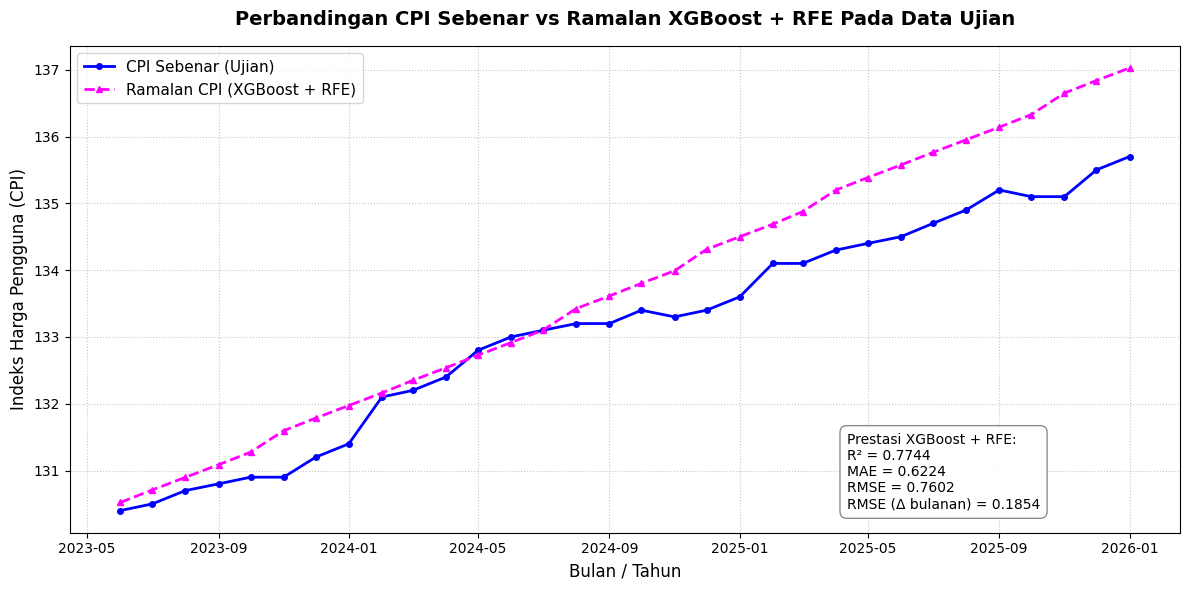

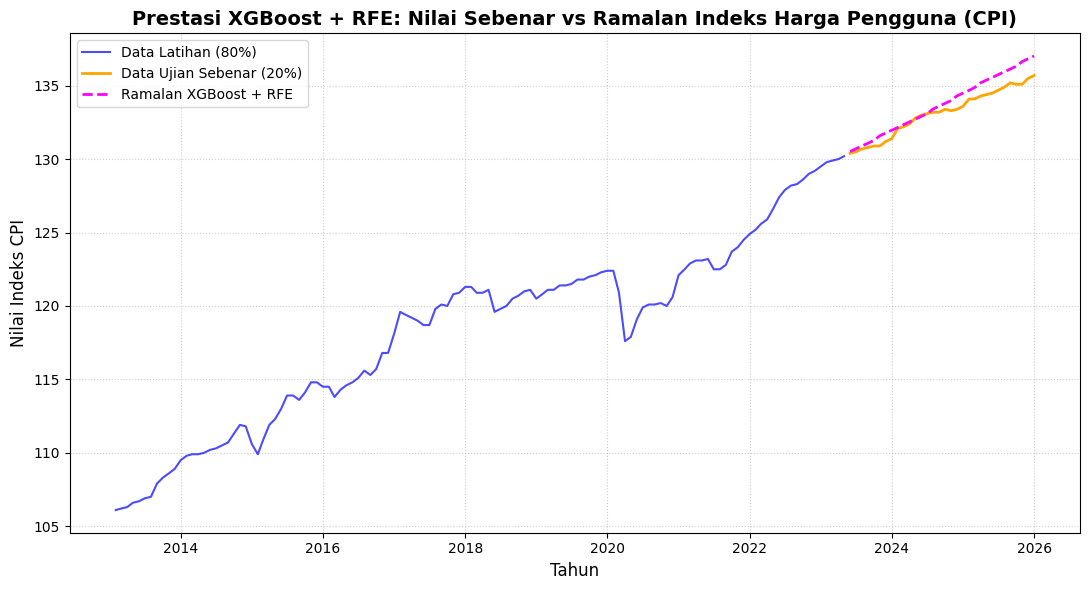

In [ ]:
# Graf: XGBoost + RFE
graf_ramalan('XGBoost + RFE', 'fuchsia', '^')
graf_latih_uji('XGBoost + RFE', 'fuchsia')

In [ ]:
# 4.4.3 XGBoost (tanpa RFE)
gs_xgb = GridSearchCV(XGBRegressor(objective='reg:squarederror', random_state=RS), grid_xgb, cv=tscv,
                      scoring='neg_mean_absolute_error', n_jobs=-1)
gs_xgb.fit(X_latih, y_latih_diff)
model_xgb = gs_xgb.best_estimator_
print("XGB tanpa RFE parameter:", gs_xgb.best_params_)
nilai('XGBoost (Tanpa RFE)', pred_diff=model_xgb.predict(X_uji))

XGB tanpa RFE parameter: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 50}
XGBoost (Tanpa RFE)                indeks: R2=0.9225 MAE=0.3631 RMSE=0.4455  |  diff: R2=-0.0814 RMSE=0.1690


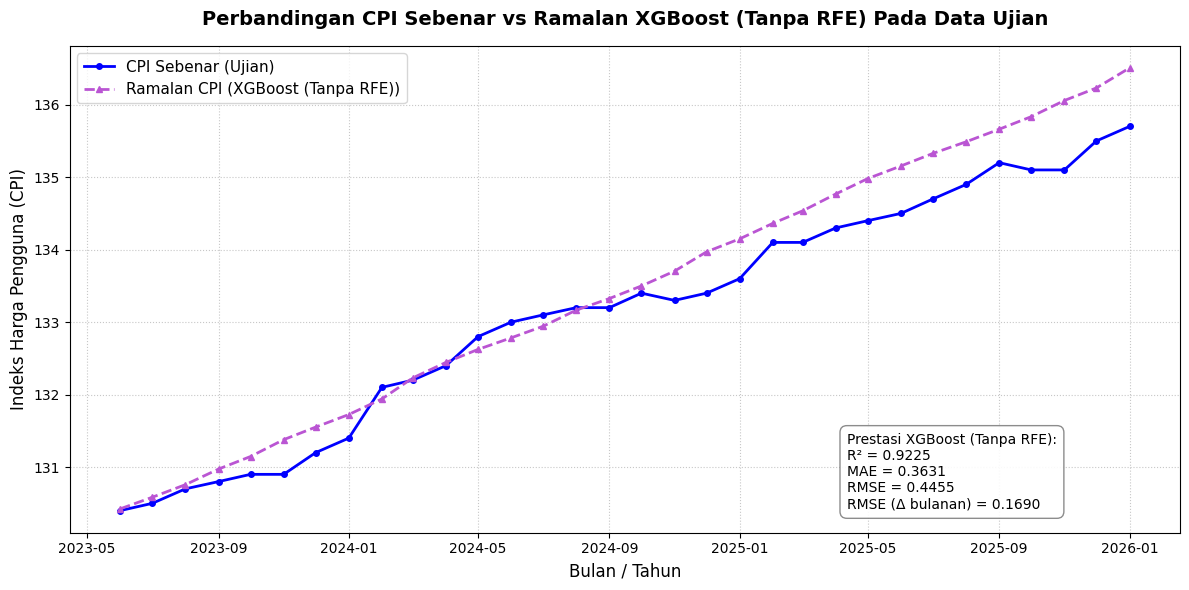

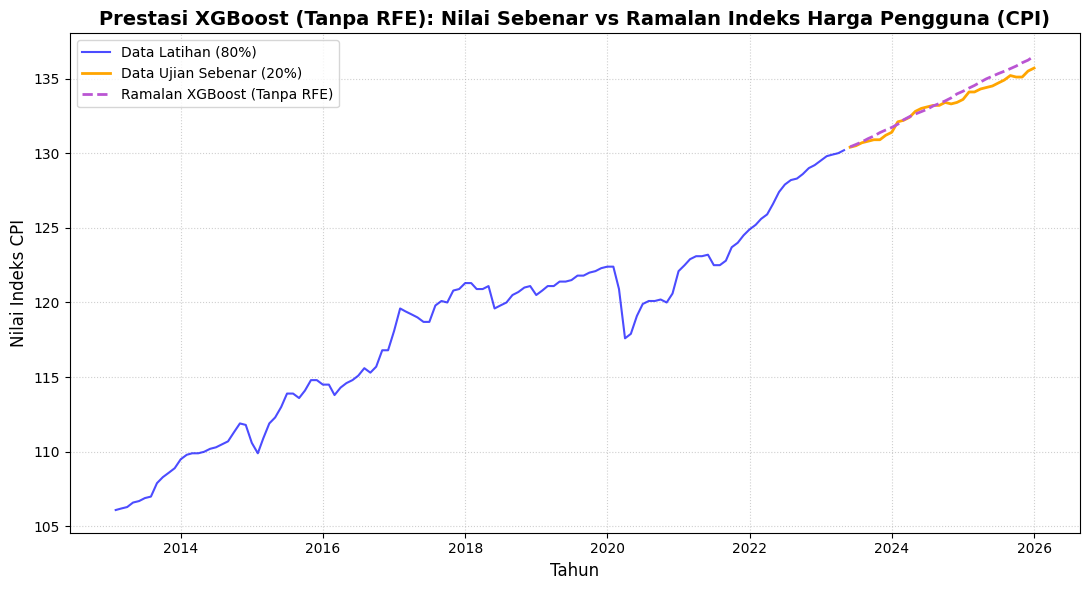

In [ ]:
# Graf: XGBoost tanpa RFE
graf_ramalan('XGBoost (Tanpa RFE)', 'mediumorchid', '^')
graf_latih_uji('XGBoost (Tanpa RFE)', 'mediumorchid')

## 6. Perbandingan Keseluruhan Model

In [ ]:
# 4.5 Jadual perbandingan
df_hasil = pd.DataFrame(hasil).reset_index(drop=True)
adalah_naif = df_hasil['Model'].str.startswith('Naif')

print("JADUAL RUMUSAN - disusun mengikut RMSE aras indeks")
print("=" * 110)
print(df_hasil.sort_values('RMSE (indeks)').round(4).to_string(index=False))
print("\nJADUAL RUMUSAN - disusun mengikut RMSE perubahan bulanan (CPI_diff)")
print("=" * 110)
print(df_hasil.sort_values('RMSE (diff)').round(4).to_string(index=False))

drift = df_hasil[df_hasil['Model'] == 'Naif: Drift'].iloc[0]
print("\n>> SEMAKAN TERHADAP PENANDA ARAS DRIFT <<")
for lajur in ['RMSE (indeks)', 'RMSE (diff)']:
    terbaik = df_hasil[~adalah_naif].sort_values(lajur).iloc[0]
    status = "MENGATASI" if terbaik[lajur] < drift[lajur] else "TIDAK mengatasi"
    print(f"{lajur:14s}: model terbaik = {terbaik['Model']} ({terbaik[lajur]:.4f}) | Drift = {drift[lajur]:.4f} -> {status} drift")

JADUAL RUMUSAN - disusun mengikut RMSE aras indeks
                      Model  R2 (indeks)  MAE (indeks)  RMSE (indeks)  R2 (diff)  MAE (diff)  RMSE (diff)
                Naif: Drift       0.9235        0.3643         0.4425    -0.0220      0.1159       0.1642
        XGBoost (Tanpa RFE)       0.9225        0.3631         0.4455    -0.0814      0.1302       0.1690
        Random Forest + RFE       0.8785        0.5057         0.5578    -0.3047      0.1424       0.1856
  Random Forest (Tanpa RFE)       0.8299        0.5418         0.6601    -0.0922      0.1311       0.1698
              XGBoost + RFE       0.7744        0.6224         0.7602    -0.3026      0.1398       0.1854
ARIMAX(0, 1, 0) (aras asal)       0.7440        0.7115         0.8097    -0.4973      0.1466       0.1988
                      Lasso       0.7437        0.6880         0.8102    -0.3295      0.1389       0.1873
                        OLS       0.7001        0.7202         0.8764    -0.4908      0.1552       0.

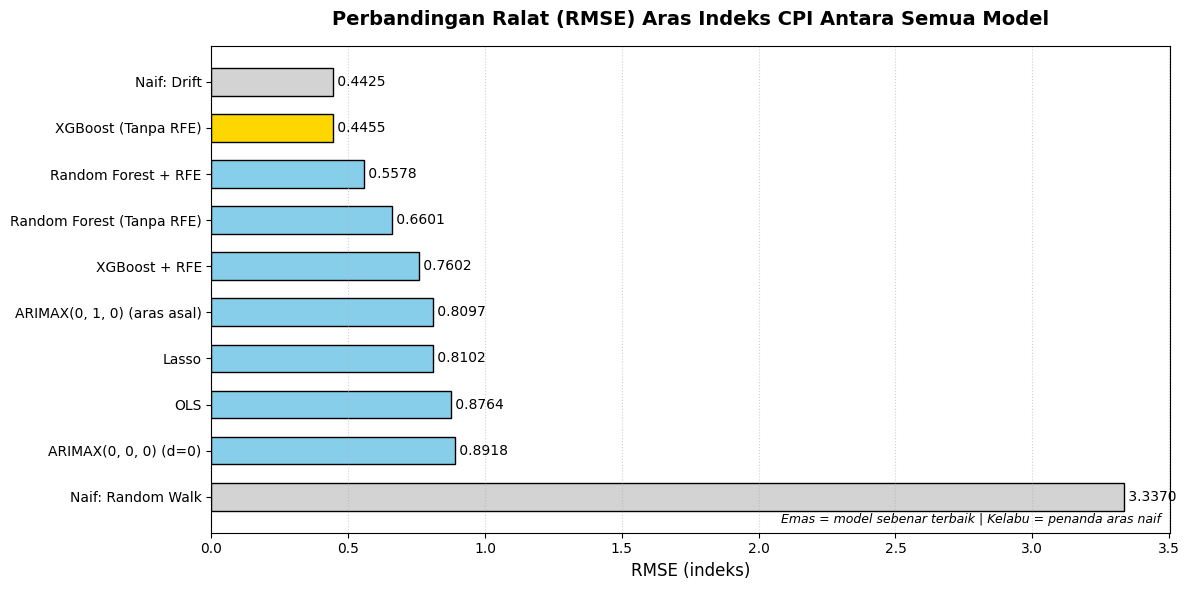

In [ ]:
# Graf: RMSE aras indeks
def graf_bar_rmse(lajur, tajuk):
    d = df_hasil.sort_values(lajur, ascending=False)
    terbaik = df_hasil[~adalah_naif].sort_values(lajur).iloc[0]['Model']
    warna = ['lightgrey' if m.startswith('Naif') else ('gold' if m == terbaik else 'skyblue') for m in d['Model']]
    plt.figure(figsize=(12, 6))
    plt.barh(d['Model'], d[lajur], color=warna, edgecolor='black', height=0.6)
    for y, v in enumerate(d[lajur]):
        plt.text(v, y, f' {v:.4f}', va='center', fontsize=10)
    plt.title(tajuk, fontsize=14, fontweight='bold', pad=15)
    plt.xlabel(lajur, fontsize=12)
    plt.grid(True, axis='x', linestyle=':', alpha=0.6)
    plt.text(0.99, 0.02, 'Emas = model sebenar terbaik | Kelabu = penanda aras naif',
             transform=plt.gca().transAxes, ha='right', fontsize=9, style='italic')
    plt.tight_layout()
    plt.show()

graf_bar_rmse('RMSE (indeks)', 'Perbandingan Ralat (RMSE) Aras Indeks CPI Antara Semua Model')

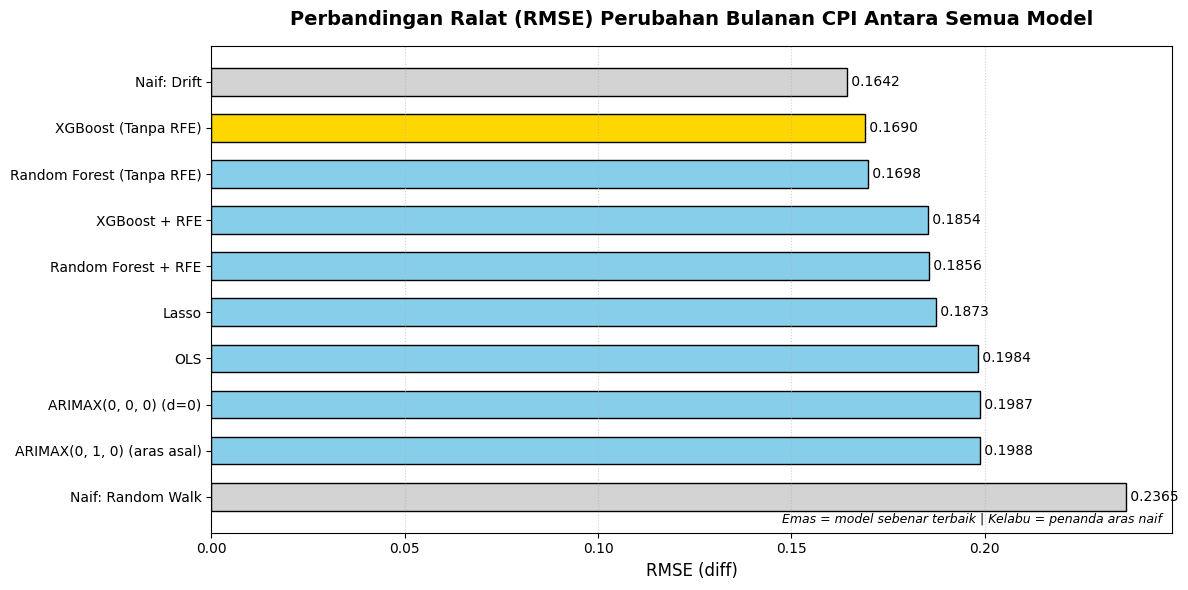

In [ ]:
# Graf: RMSE perubahan bulanan
graf_bar_rmse('RMSE (diff)', 'Perbandingan Ralat (RMSE) Perubahan Bulanan CPI Antara Semua Model')

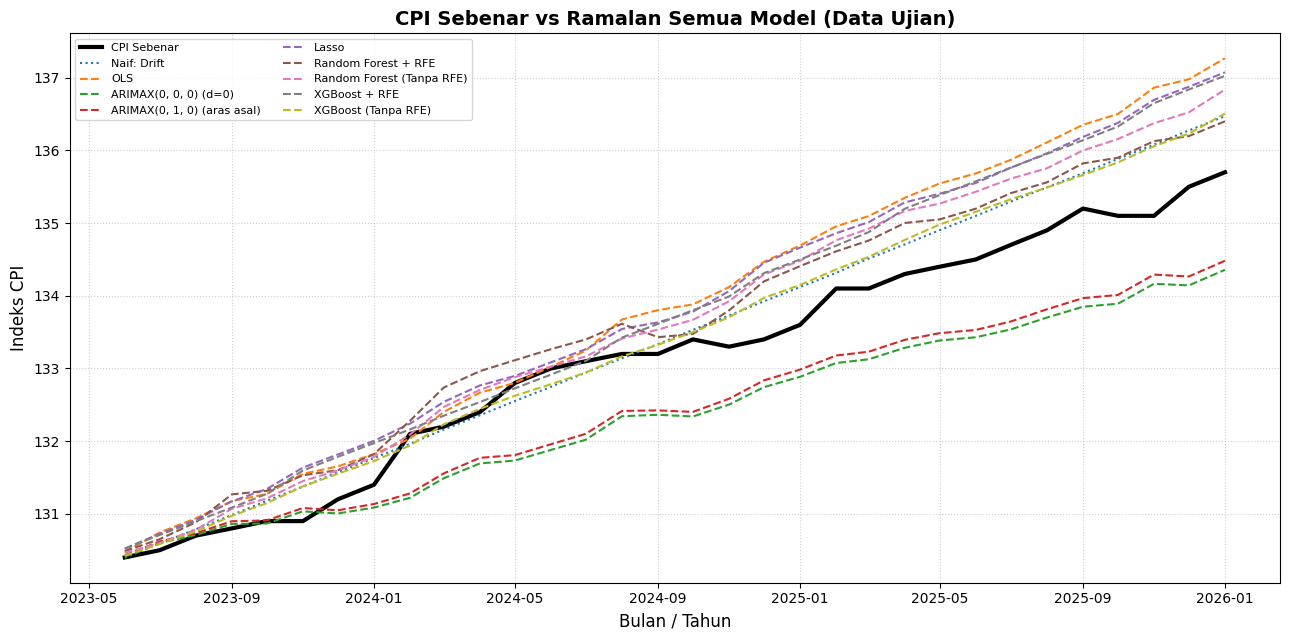

In [ ]:
# Graf: semua ramalan dalam satu graf
plt.figure(figsize=(13, 6.5))
plt.plot(y_uji_asal.index, y_uji_asal.values, 'k-', linewidth=3, label='CPI Sebenar')
for nama, pr in ramalan_index.items():
    if 'Random Walk' in nama:
        continue                                   # dibuang kerana mengherotkan skala
    plt.plot(y_uji_asal.index, pr, linestyle=':' if nama.startswith('Naif') else '--', linewidth=1.5, label=nama)
plt.title('CPI Sebenar vs Ramalan Semua Model (Data Ujian)', fontsize=14, fontweight='bold')
plt.xlabel('Bulan / Tahun', fontsize=12); plt.ylabel('Indeks CPI', fontsize=12)
plt.legend(fontsize=8, ncol=2); plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

## 7. Ujian Kepekaan
Model utama menggunakan nilai X **bulan yang sama** dengan CPI (hubungan serentak). Dalam peramalan sebenar, nilai X bulan semasa belum diketahui.
Ujian ini menggantikan X dengan nilai **berlengah 1 bulan** untuk menilai prestasi dalam keadaan peramalan yang lebih realistik.

In [ ]:
# Kepekaan: X berlengah 1 bulan
X_lag = df_bersih[senarai_x].shift(1).dropna()
y_lag = df_bersih['CPI_diff'].loc[X_lag.index]
sempadan = X_uji.index[0]
XL_latih, XL_uji = X_lag[X_lag.index < sempadan], X_lag[X_lag.index >= sempadan]
yL_latih = y_lag[y_lag.index < sempadan]

gs_lag = GridSearchCV(pipe_lasso, {'lasso__alpha': np.logspace(-4, 1, 30)}, cv=tscv,
                      scoring='neg_mean_absolute_error', n_jobs=-1).fit(XL_latih, yL_latih)
print("Lasso dengan X berlengah 1 bulan | alpha =", gs_lag.best_params_['lasso__alpha'])
print("Pekali:", dict(zip(senarai_x, gs_lag.best_estimator_.named_steps['lasso'].coef_.round(4))))
nilai('Lasso (X lag-1)', pred_diff=gs_lag.best_estimator_.predict(XL_uji))

Lasso dengan X berlengah 1 bulan | alpha = 0.12689610031679235
Pekali: {'OPR_Rate_diff': np.float64(0.0), 'PPI_Index_diff': np.float64(0.1003), 'Unemployment_Rate_diff': np.float64(-0.0), 'M3_Total_diff': np.float64(0.0), 'USD_Avg_diff': np.float64(-0.0)}
Lasso (X lag-1)                    indeks: R2=0.9817 MAE=0.1761 RMSE=0.2164  |  diff: R2=-0.1405 RMSE=0.1735


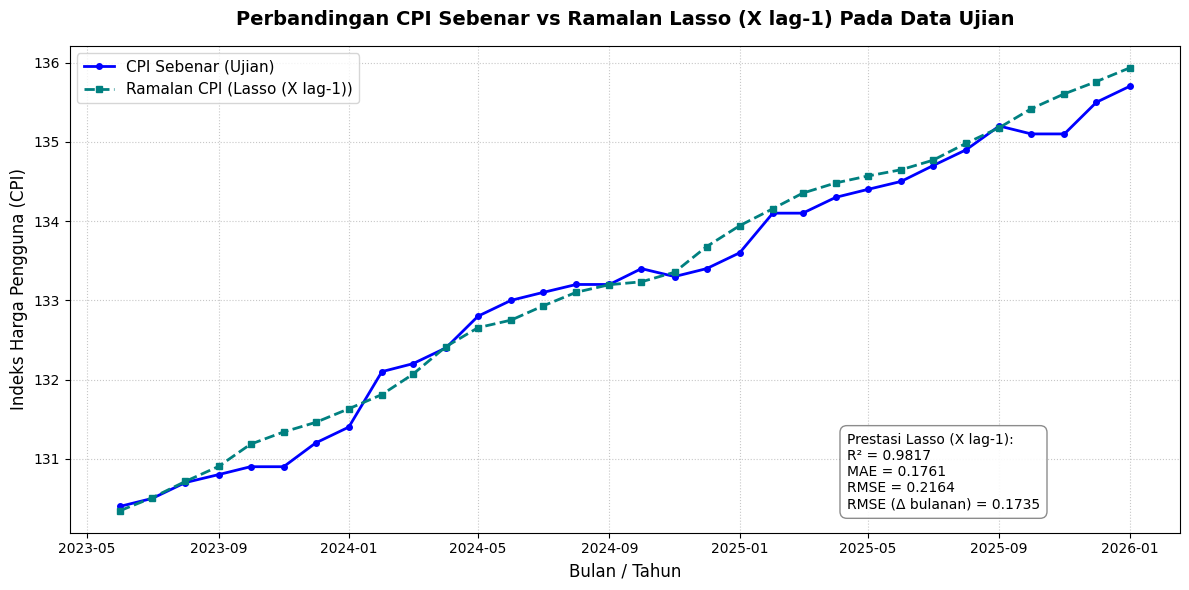

In [ ]:
# Graf: Lasso (X lag-1)
graf_ramalan('Lasso (X lag-1)', 'teal', 's', tajuk_pendek='Lasso (X lag-1)')

## 8. Kebolehtafsiran Model
### 8.1 Kepentingan ciri

                        Lasso |pekali|  RF (impurity)  XGB (gain)
Pembolehubah                                                     
OPR_Rate_diff                   0.0000         0.0045      0.0000
PPI_Index_diff                  0.0666         0.2576      0.1466
Unemployment_Rate_diff          0.2521         0.5273      0.5891
M3_Total_diff                   0.0000         0.1252      0.1371
USD_Avg_diff                    0.0002         0.0853      0.1271


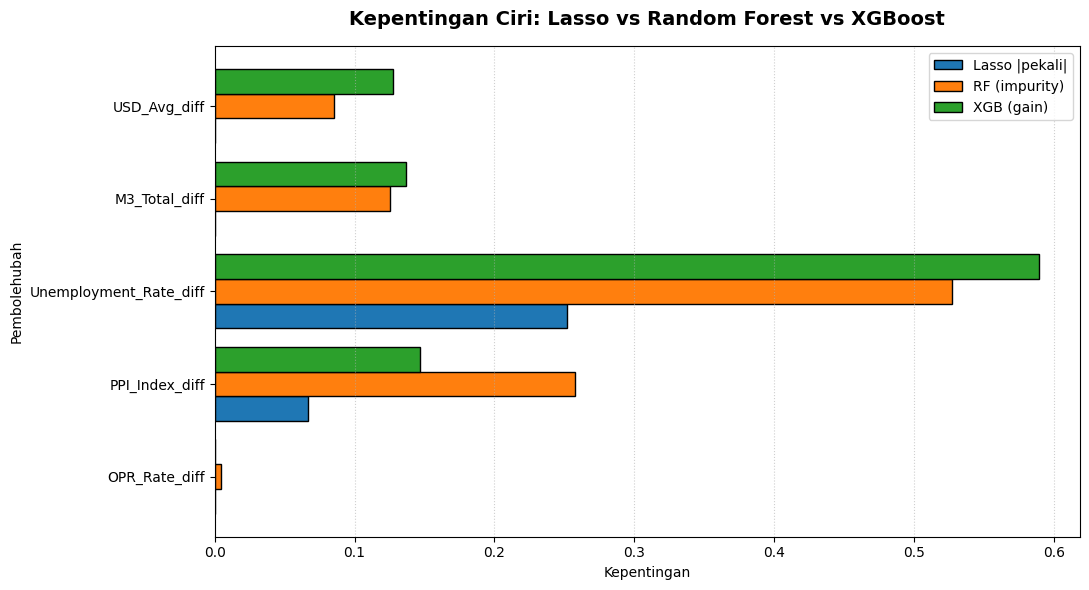

In [ ]:
# 4.6.1 Kepentingan ciri
df_imp = pd.DataFrame({
    'Pembolehubah': senarai_x,
    'Lasso |pekali|': np.abs(model_lasso.named_steps['lasso'].coef_),
    'RF (impurity)': model_rf.feature_importances_,
    'XGB (gain)': model_xgb.feature_importances_,
}).set_index('Pembolehubah')
print(df_imp.round(4))

df_imp.plot(kind='barh', figsize=(11, 6), edgecolor='black', width=0.8)
plt.title('Kepentingan Ciri: Lasso vs Random Forest vs XGBoost', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kepentingan'); plt.grid(True, axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 8.2 Analisis SHAP (XGBoost tanpa RFE)

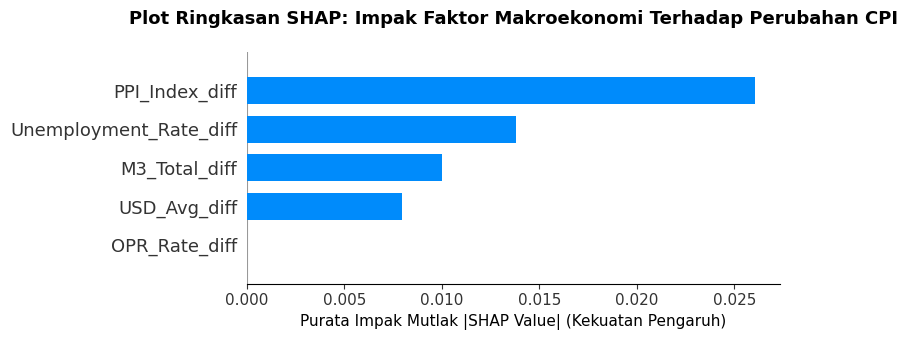

In [ ]:
# 4.6.2 SHAP: bar
sv_xgb = shap.TreeExplainer(model_xgb)(X_uji)

plt.figure(figsize=(10, 6))
shap.summary_plot(sv_xgb, X_uji, plot_type='bar', show=False)
plt.title('Plot Ringkasan SHAP: Impak Faktor Makroekonomi Terhadap Perubahan CPI', fontsize=13, fontweight='bold', pad=20)
plt.xlabel('Purata Impak Mutlak |SHAP Value| (Kekuatan Pengaruh)', fontsize=11)
plt.tight_layout()
plt.show()

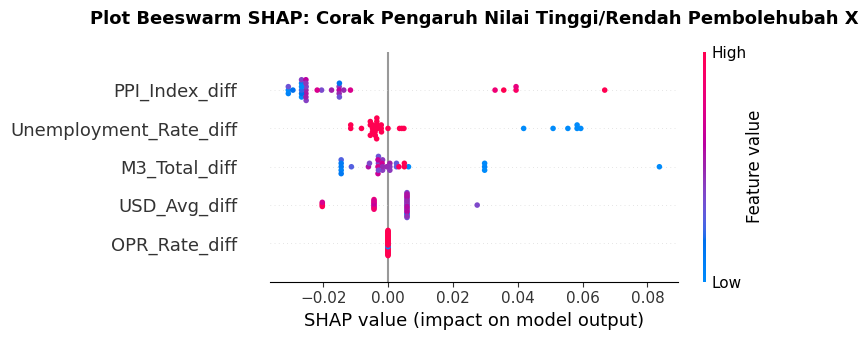

In [ ]:
# SHAP: beeswarm
plt.figure(figsize=(10, 6))
shap.summary_plot(sv_xgb, X_uji, show=False)
plt.title('Plot Beeswarm SHAP: Corak Pengaruh Nilai Tinggi/Rendah Pembolehubah X', fontsize=13, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

Algoritma           Lasso  Random Forest  XGBoost
Pembolehubah                                     
M3_Total           0.0000         0.0239   0.0100
OPR_Rate           0.0000         0.0003   0.0000
PPI_Index          0.0353         0.0526   0.0260
USD_Avg            0.0001         0.0112   0.0079
Unemployment_Rate  0.0421         0.0246   0.0138


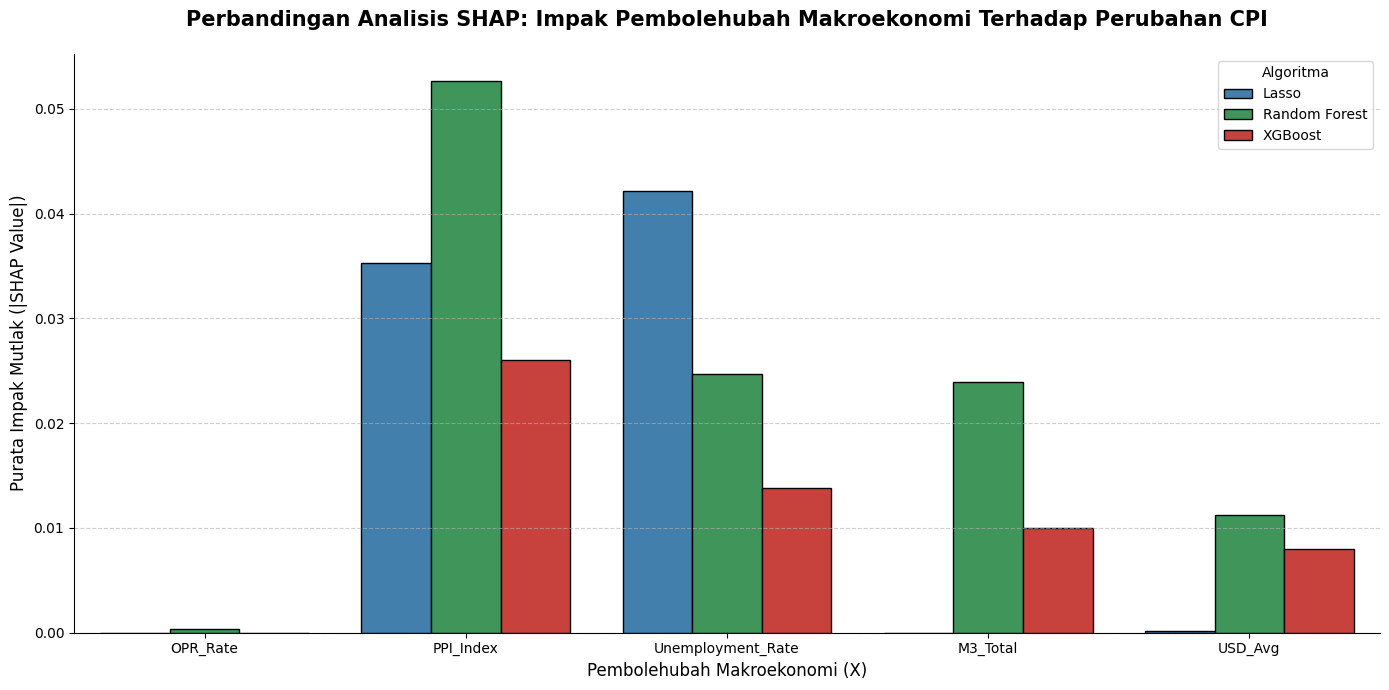

In [ ]:
# SHAP: perbandingan Lasso vs Random Forest vs XGBoost
nama_bersih = {c: (c[:-5] if c.endswith('_diff') else c) for c in senarai_x}

def shap_tree(model, X, nama):
    v = shap.TreeExplainer(model).shap_values(X)
    return pd.DataFrame({'Pembolehubah': [nama_bersih[c] for c in X.columns],
                         'Purata |SHAP|': np.abs(v).mean(axis=0), 'Algoritma': nama})

skala = model_lasso.named_steps['scaler']
X_latih_s, X_uji_s = skala.transform(X_latih), skala.transform(X_uji)
v_lasso = shap.LinearExplainer(model_lasso.named_steps['lasso'], X_latih_s).shap_values(X_uji_s)
df_shap_lasso = pd.DataFrame({'Pembolehubah': [nama_bersih[c] for c in senarai_x],
                              'Purata |SHAP|': np.abs(v_lasso).mean(axis=0), 'Algoritma': 'Lasso'})

df_shap = pd.concat([df_shap_lasso, shap_tree(model_rf, X_uji, 'Random Forest'),
                     shap_tree(model_xgb, X_uji, 'XGBoost')], ignore_index=True)
print(df_shap.pivot(index='Pembolehubah', columns='Algoritma', values='Purata |SHAP|').round(4))

plt.figure(figsize=(14, 7))
sns.barplot(data=df_shap, x='Pembolehubah', y='Purata |SHAP|', hue='Algoritma',
            palette=['#3182bd', '#31a354', '#de2d26'], edgecolor='black', errorbar=None)
plt.title('Perbandingan Analisis SHAP: Impak Pembolehubah Makroekonomi Terhadap Perubahan CPI',
          fontsize=15, fontweight='bold', pad=20)
plt.xlabel('Pembolehubah Makroekonomi (X)', fontsize=12)
plt.ylabel('Purata Impak Mutlak (|SHAP Value|)', fontsize=12)
plt.grid(True, axis='y', linestyle='--', alpha=0.6)
sns.despine()
plt.tight_layout()
plt.show()